**Imports** Run the model from t=0 upto t=20 by using different beta values

In [ ]:
!py simulate_abm.py --num-infected 1 --num-steps 5 --gamma 10 \
  --beta-start 0.0 --beta-step 0.05 --beta-count 20 \
  --tau 0 --runs 20 --out abm_bank_all_5_test.npz 

Simulated agent spread by using an ABM,
Visualized infection states on a grid, 
Calculated  distances of the infected agents from the center,
plotted the distance distribution.

**Difference in the number of infected in simulated and obs**

Estimates β by comparing the simulated number of infected agents at step 20 with the observed infected from the CSV, selecting the β with the smallest difference. 

Compares simulated and observed radious distance distributions of infected agents from the grid center for different β values.

Runs simulations for each β and plots histograms of infected distances.

Plots the observed distance distribution from CSV data.

Computes the difference between simulated and observed distributions to estimate the β with the closest match.

Combine all beta estimations methods in line plots

Plotting by using the new particle_filter.p file 

In [ ]:
import os
import numpy as np
from particle_filter_abm_a_di import (
    run_simulations,
    plot_half,
    get_all_simulations,
    plot_all_runs, 
    plot_mean_betas,
    plot_all_vs_half,
    export_mean_betas_to_csv
)

simulation_data = "abm_bank_all_5_test.npz"
obs = "agent_data.csv"

t_start = 5
t_final = 420
window  = 5

os.makedirs(f"figsa_{window}", exist_ok=True)

run_simulations(
    observed_csv=obs,
    bank_path=simulation_data,
    t_start=t_start, t_final=t_final, window=window,
    run_replicates=2, gamma=10,
    append_back_to_bank=True,
    beta_start=0.0,
    beta_step=0.05,
    beta_count=20,
)



beta_xlim  = (0.0, 1.5)
beta_xtick = np.arange(0.0, 1.5, 0.1)

#for t in range(t_start, t_final + 1, window):
    
#    plot_half(
#        simulation_data,
#        t=t,
#        title=f"Lower half at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figs_a/lower_half_t{t}.pdf",
#        show=False,
#        close=True
#    )    

#for t in range(t_start + window, t_final + 1, window):
    
#    bA_all, dA_all = get_all_simulations(simulation_data, t=t)
#    plot_all_runs(
#        betas_A=bA_all, dA=dA_all,
#        title=f"All runs at t={t}",
#        xlim=beta_xlim,
#        xtick=beta_xtick,
#        save_path=f"figs_a/all_runs_t{t}.pdf",
#        show=False,
#        close=True
#    )



for t in range(t_start + window, t_final + 1, window):
    plot_all_vs_half(
        bank_path=simulation_data,
        t=t,
        title=f"All runs at t={t}",
        xlim=beta_xlim,
        xtick=beta_xtick,
        save_path=f"figsa_{window}/all_vs_half_t{t}.pdf",
        show=False,
        close=True,
    )

time_xlim  = (0, t_final+2)
time_xtick = np.arange(0, t_final+2, 3*window) 


plot_mean_betas(
    bank_path=simulation_data,
    title=f'Rolling window = {window}',
    overlay_csv_path="agent_data.csv",         
    save_path=f"figsa_{window}/SABL_{window}.pdf",
    xlim=time_xlim,
    ylim=beta_xlim, 
    xtick=time_xtick,
    ytick=beta_xtick,
    #show=False,
    #close=True
)

export_mean_betas_to_csv(
    bank_path=simulation_data,
    out_csv=f"estimated_beta_SABL_{window}.csv",
)

In [ ]:
!py particle_filter_abm_a_dist_inf_plot.py \
  --bank-path abm_bank_all_5.npz \
  --observed-csv agent_data.csv \
  --mode over_time \
  --t-max 420 \
  --save figa/infected_over_time_A.png

In [ ]:
import numpy as np
from Beta_plots import plot_mean_betas_multi

t_final = 420


WINDOWS = [5, 10, 15, 20]

BANKS = {
    5:  "abm_bank_all_5.npz",
    10: "abm_bank_all_10.npz",
    15: "abm_bank_all_15.npz",
    20: "abm_bank_all_20.npz",
}

COLORS = {
    5:  "blue",
    10: "gold",
    15: "green",
    20: "red",
}

SELECT = [5, 10, 15, 20]        

plot_mean_betas_multi(
    bank_paths=[BANKS[w] for w in SELECT],
    labels=[f"window={w}" for w in SELECT],
    observed_csv_path="agent_data.csv",
    save_path="figs_multi/SABL_estimated_beta.png",
    xlim=(0, t_final+1),
    xtick=np.arange(0, t_final+1, 20),
    ylim=(0.0, 1.501),
    ytick=np.arange(0.0, 1.501, 0.15),
    line_colors=[COLORS[w] for w in SELECT],
    line_alphas=[1.0 for _ in SELECT],
    ci_colors=[COLORS[w] for w in SELECT],
    ci_alphas=[0.2 for _ in SELECT],
    observed_marker="*",
    observed_size=3,
)

Saved: figs_multi/infected_windows_subplots_SABL.png


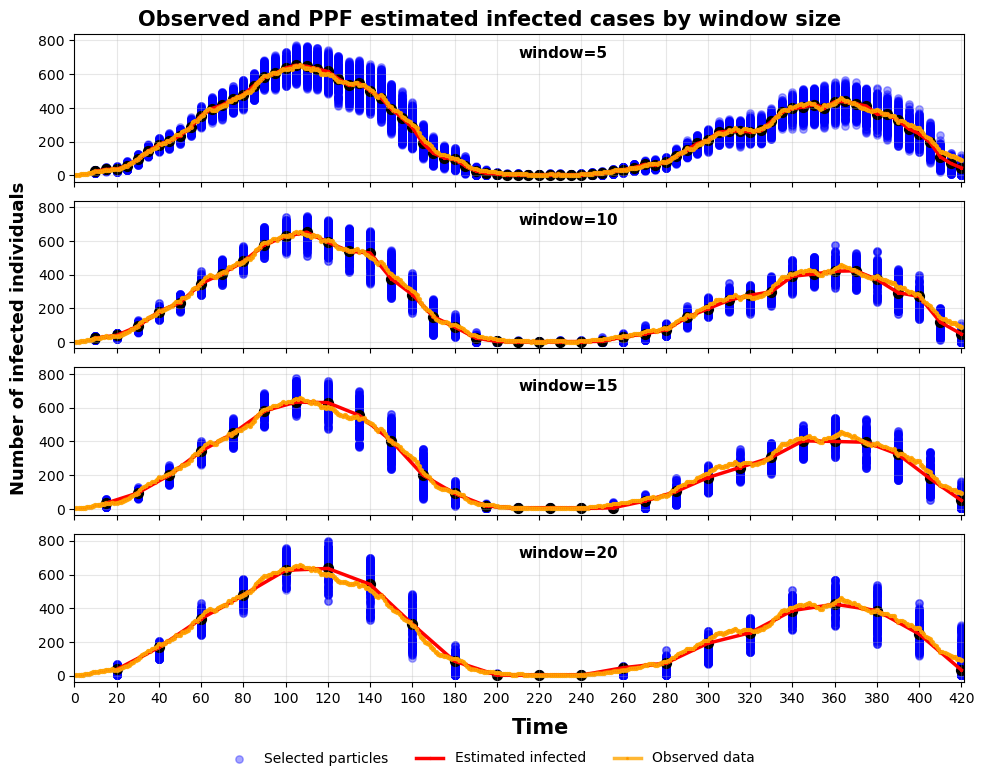

In [1]:
import numpy as np
from infected_plot import plot_selected_infected_multi_subplots

t_final = 420

plot_selected_infected_multi_subplots(
    bank_paths=[
        "abm_bank_all_5.npz",
        "abm_bank_all_10.npz",
        "abm_bank_all_15.npz",
        "abm_bank_all_20.npz",
    ],
    labels=["window=5", "window=10", "window=15", "window=20"],
    observed_csv_path="agent_data.csv",
    save_path="figs_multi/infected_windows_subplots_SABL.png",
    t_max=420,
    xlim=(0, t_final+1),
    xtick=np.arange(0, t_final + 1, 20),
    show=True,
    close=True,
)


In [ ]:
!py window_error.py sweep \
  --banks "5=abm_bank_all_5.npz,10=abm_bank_all_10.npz,15=abm_bank_all_15.npz,20=abm_bank_all_20.npz" \
  --observed-csv agent_data.csv \
  --metrics-path window_metrics_SABL.npz \
  --t-max 420

In [ ]:
!py window_error.py box --metrics-path window_metrics_SABL.npz  --save-fig

In [1]:
!py AE.py --metrics-sabl window_metrics_SABL.npz --metrics-abl window_metrics_ABL.npz --metrics-sir window_metrics_ABL_SIR.npz --fig-name AE_Synthetic.pdf

Saved plot to: AE_Synthetic.pdf


c:\Users\user\Desktop\PhD\FinaL ONE\Code finalized\Synthetic data\SABL\For a firmula\Gride-Based\Gride-graph\G_Based\AE.py:31: SyntaxWarning: invalid escape sequence '\d'
  m = re.search(r"window_(\d+)_abs_err$", k)


In [1]:
from make_pf_video_infected import make_pf_video_beta_vs_infected

make_pf_video_beta_vs_infected(
    bank_path="abm_bank_all_5.npz",
    observed_csv="gent_data.csv",   
    out_path="Estimated_beta_videos_distance_SABL.gif",
    fps=3,
)


'Estimated_beta_videos_distance_SABL.gif'

In [ ]:
import numpy as np
import os

def _pf_results_path(bank_path: str) -> str:
    root, _ = os.path.splitext(bank_path)
    return root + "_pf_results.npz"

def _load_path_for_plots(path: str) -> str:
    pf = _pf_results_path(path)
    return pf if os.path.exists(pf) else path

def read_beta_at_t(bank_path: str, t: int):
    bank_path = _load_path_for_plots(bank_path)

    k_mean = f"t{t}_A_half_mean_beta"
    k_ci   = f"t{t}_A_half_mean_beta_ci"

    with np.load(bank_path, allow_pickle=True) as d:
        if k_mean not in d.files:
            raise KeyError(f"Missing key: {k_mean}")
        mean_arr = np.asarray(d[k_mean]).ravel()
        mean_beta = float(mean_arr[0]) if mean_arr.size else float("nan")

        lo = hi = float("nan")
        if k_ci in d.files:
            ci_arr = np.asarray(d[k_ci]).ravel()
            if ci_arr.size >= 2 and np.isfinite(ci_arr[:2]).all():
                lo, hi = float(ci_arr[0]), float(ci_arr[1])

    return mean_beta, lo, hi

mean60, lo60, hi60 = read_beta_at_t("abm_bank_all_20.npz", 300)
print("t=60 mean beta:", mean60)
print("t=60 CI:", (lo60, hi60))

In [ ]:
!py particle_filter_abm_a_dist_inf_plot.py --bank-path abm_bank_all_5.npz --observed-csv agent_data.csv --t-print 420

In [ ]:

import numpy as np
from Beta_plots import plot_posterior_at_time

plot_posterior_at_time(
    bank_path="abm_bank_all_5.npz",
    time_point=60,
    observed_csv_path="gent_data.csv",
    save_path="figs/posterior_t2360_5.pdf"
)

Totoal points error

In [ ]:
import numpy as np
import pandas as pd
import os
import re


def _pf_results_path(bank_path: str) -> str:
    root, _ = os.path.splitext(bank_path)
    return root + "_pf_results.npz"


def _load_path_for_plots(path: str) -> str:
    pf = _pf_results_path(path)
    return pf if os.path.exists(pf) else path

bank_path = "abm_bank_all_10.npz"
observed_csv = "gent_data.csv"


tau = 10
t_start = 10
t_final = 420

csv_time_starts_from = 1

bank_path = _load_path_for_plots(bank_path)
data = np.load(bank_path, allow_pickle=True)
pattern = re.compile(rf"^t(\d+)_A_half_mean_beta$")

times = sorted(
    int(m.group(1))
    for key in data.files
    if (m := pattern.match(key))
)

times = [t for t in times if t_start <= t <= t_final]

df = pd.read_csv(observed_csv)

if "Beta" not in df.columns:
    raise KeyError("Column 'Beta' not found in observed CSV file.")

beta_obs = df["Beta"].values
T = len(beta_obs)

total_error = 0.0
count = 0
N_f = 0

rows = []

for idx in range(len(times) - 1):

    t_k = times[idx]
    t_k1 = times[idx + 1]

    if t_k1 - t_k != tau:
        continue

    key_k = f"t{t_k}_A_half_mean_beta"
    key_k1 = f"t{t_k1}_A_half_mean_beta"

    if key_k not in data.files or key_k1 not in data.files:
        continue

    beta_k = float(np.asarray(data[key_k]).ravel()[0])
    beta_k1 = float(np.asarray(data[key_k1]).ravel()[0])

    for j in range(tau):

        t = t_k + j

    
        obs_index = t - csv_time_starts_from

        if obs_index < 0 or obs_index >= T:
            continue

        beta_true = float(beta_obs[obs_index])

        beta_est = beta_k + ((beta_k1 - beta_k) / tau) * j

        abs_error = abs(beta_true - beta_est)

        total_error += abs_error
        count += 1

        rows.append({
            "interval": f"{t_k}-{t_k1}",
            "t_k": t_k,
            "t_k1": t_k1,
            "j": j,
            "t": t,
            "obs_index_used": obs_index,
            "beta_observed": beta_true,
            "beta_interp": beta_est,
            "absolute_error": abs_error
        })

    N_f += 1


MAE_formula = total_error / (N_f * tau) 
#MAE_count = total_error / count 

result_df = pd.DataFrame(rows)


#print(result_df)
#print(N_f * tau)
#print("Total error:", total_error)
print("MAE:", MAE_formula)

In [ ]:
import numpy as np
import pandas as pd
import os
import re


def _pf_results_path(bank_path: str) -> str:
    root, _ = os.path.splitext(bank_path)
    return root + "_pf_results.npz"


def _load_path_for_plots(path: str) -> str:
    pf = _pf_results_path(path)
    return pf if os.path.exists(pf) else path



bank_path = "abm_bank_all_15.npz"
observed_csv = "gent_data.csv"


t_start = 15
t_final = 420

csv_time_starts_from = 1


bank_path = _load_path_for_plots(bank_path)
data = np.load(bank_path, allow_pickle=True)

df = pd.read_csv(observed_csv)

if "Beta" not in df.columns:
    raise KeyError("Column 'Beta' not found in observed CSV file.")

beta_obs = df["Beta"].values

pattern = re.compile(rf"^t(\d+)_A_half_mean_beta$")

times = sorted(
    int(m.group(1))
    for key in data.files
    if (m := pattern.match(key))
)

times = [t for t in times if t_start <= t <= t_final]

total_error = 0.0
N_f = 0

rows = []

for t_k in times:

    key_k = f"t{t_k}_A_half_mean_beta"

    if key_k not in data.files:
        print(f"Missing key: {key_k}")
        continue

    beta_hat = float(np.asarray(data[key_k]).ravel()[0])

    obs_index = t_k - csv_time_starts_from

    if obs_index < 0 or obs_index >= len(beta_obs):
        continue

    beta_true = float(beta_obs[obs_index])

    error = abs(beta_true - beta_hat)

    total_error += error
    N_f += 1

    rows.append({
        "t_k": t_k,
        "obs_used": obs_index,
        "beta_observed": beta_true,
        "beta_estimated": beta_hat,
        "error": error
    })


MAE = total_error / N_f 

result_df = pd.DataFrame(rows)



#print(result_df)
#print("\nTotal absolute error:", total_error)
print("Mean Absolute Error (MAE):", MAE)

In [ ]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from packages.abm.abm import ABM
from packages.abm.agent import Agent


Tmax = 501
CSV_Path = "agent_data.csv"
Beta_CSV = "beta_0.1_0.9.csv"


CASES_CSV_Path = "gent_data.csv"

num_infected = 1
gamma = 10
init_tau = 0

np.random.seed(0)


def load_beta_schedule(path: str):
    changes = {}
    rows = []
    with open(path, "r", newline="") as f:
        r = csv.DictReader(f)
        for row in r:
            t = int(float(row["Time"]))
            b = float(row["Beta"])
            rows.append((t, b))

    rows.sort(key=lambda x: x[0])
    default_beta = rows[0][1]

    for t, b in rows:
        if t >= 1:
            changes[t] = b

    return default_beta, changes


default_beta, beta_changes = load_beta_schedule(Beta_CSV)


model = ABM(
    num_infected=num_infected,
    beta=default_beta,
    gamma=gamma,
    init_tau=init_tau,
)


with open(CSV_Path, "w", newline="") as f:
    csv.writer(f).writerow(
        ["Time", "Beta", "X", "Y", "Status", "Days_infected"]
    )


for t in range(1, Tmax + 1):

    if t in beta_changes:
        model.beta = beta_changes[t]

    model.run_simulation(1)

    rows = []
    for (x, y), a in model.agents.items():
        tau = int(a.days_infected) if a.status == Agent.I else 0
        rows.append([
            t,
            float(model.beta),
            x,
            y,
            a.status,
            tau
        ])

    with open(CSV_Path, "a", newline="") as f:
        csv.writer(f).writerows(rows)



df = pd.read_csv(CSV_Path)

cases_df = (
    df.groupby("Time")
      .agg(
          Beta=("Beta", "first"),
          Infected=("Status", lambda s: (s == Agent.I).sum()),
          Recovered=("Status", lambda s: (s == Agent.R).sum()),
      )
      .reset_index()
)

cases_df.to_csv(CASES_CSV_Path, index=False)


I_counts = (
    df.groupby("Time")["Status"]
      .apply(lambda s: (s == Agent.I).sum())
)

plt.figure(figsize=(7, 4.8))
plt.plot(I_counts.index, I_counts.values, label="Infected")
plt.xlabel("Time")
plt.ylabel("Number of agents")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [2]:

!py particles_infected.py \
  --bank-path abm_bank_all_10.npz \
  --observed-csv gent_data.csv \
  --nrows 3\
  --ncols 5\
  --window 10 --t-end 320 \
  --save figs/particles_infected_beta_SABL.png\
  --show
